# Лабораторная работа №3. Фильтрация шумов на изображениях

**Цель:** исследовать подавление аддитивного белого гауссовского и импульсного
шума самостоятельно реализованными линейными и медианными фильтрами.

## 1. Модели, метрики и условия эксперимента

Аддитивная модель: $y=x+v$, $v\sim\mathcal N(0,D_v)$,
$D_v=D_x/d^2$, где $d^2\in\{10,1\}$ — отношение дисперсий, не децибелы.
Импульсная модель: с вероятностью $p\in\{0.1,0.3\}$ пиксель заменяется
равновероятно на 0 или 255. На бинарном исходном изображении замена может совпасть
с исходной яркостью, поэтому доля фактически изменённых пикселей ожидается около $p/2$.

$$\varepsilon^2=\operatorname{MSE}(\hat x,x)
=\frac1{MN}\sum_{m,n}(\hat x(m,n)-x(m,n))^2,\qquad
K_c=\frac{\operatorname{MSE}(\hat x,x)}{\operatorname{MSE}(y,x)}.$$

$K_c<1$ означает улучшение. Для обоих проходов знаменатель один и тот же:
ошибка исходного зашумлённого изображения. Это MSE (квадрат СКО), а не RMSE.
Дисперсия вычисляется по всем пикселям с делением на $MN$ (`ddof=0`).
Все расчёты выполняются в `float64`, без округления и обрезки яркостей.
Только отображение изображений ограничено диапазоном 0–255.
Окна имеют размер $3\times3$; границы отражаются без повторения крайнего пикселя
(`numpy.pad(..., mode='reflect')`).

В начале подключаются NumPy для вычислений, Matplotlib для построения графиков
и средства IPython для вывода таблиц. Для номера `N = 27` по формулам методички
получаются размер клетки `CELL_SIZE = 24` и начальное состояние генератора
случайных чисел `SEED = 1027`. Размер изображения задаётся константой `SIZE = 128`.

Функция `checkerboard` создаёт массив координат каждого пикселя. Целочисленное
деление координат на размер клетки определяет номер клетки по каждой оси;
чётность суммы этих номеров задаёт чередование яркостей 0 и 255.
Полученный массив `x` служит эталоном во всех экспериментах.

Функция `mse` переводит массивы в вещественный тип, вычисляет поэлементную
разность, возводит её в квадрат и усредняет. Функция `quality` возвращает MSE
и отношение этой ошибки к ошибке зашумлённого изображения. При нулевом
знаменателе возвращается `NaN`, поскольку коэффициент не определён.
В конце выводятся параметры, средняя яркость и дисперсия `dx` исходного поля.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

N = 27
SIZE = 128
CELL_SIZE = 8 + 2 * ((N - 1) % 9)
SEED = 1000 + N
assert 1 <= N <= 30
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'figure.dpi': 110})

def checkerboard(size, cell_size):
    rows, cols = np.indices((size, size))
    return (((rows // cell_size + cols // cell_size) % 2) * 255).astype(np.float64)

def mse(estimate, reference):
    difference = np.asarray(estimate, dtype=np.float64) - np.asarray(reference, dtype=np.float64)
    return float(np.mean(difference ** 2))

def quality(estimate, reference, noisy):
    error = mse(estimate, reference)
    baseline = mse(noisy, reference)
    return error, error / baseline if baseline != 0 else float('nan')

x = checkerboard(SIZE, CELL_SIZE)
dx = float(np.var(x, ddof=0))
display(Markdown(f'**Параметры:** N = {N}; размер {SIZE}×{SIZE}; '
                 f'клетка {CELL_SIZE}×{CELL_SIZE}; seed = {SEED}; границы reflect.  \n'
                 f'**Средняя яркость:** {x.mean():.6f}; **Dₓ:** {dx:.6f}. '
                 'Крайние клетки обрезаются границами кадра.'))

**Параметры:** N = 27; размер 128×128; клетка 24×24; seed = 1027; границы reflect.  
**Средняя яркость:** 125.507812; **Dₓ:** 16252.281189. Крайние клетки обрезаются границами кадра.

## 2. Самостоятельная реализация семи фильтров

Линейная фильтрация вычисляет сумму произведений значений окна и коэффициентов
маски. Маска разворачивается по обеим осям для свёртки; для симметричных $A_i$
это совпадает с корреляцией. Нормировка масок: $A_1=\mathbf1/9$,
$A_2=(\mathbf1+E_{22})/10$ и $A_3=[1,2,1]^T[1,2,1]/16$.

Для медианного фильтра значения окна повторяются согласно целочисленным весам,
сортируются, затем выбирается центральный элемент. Нулевой вес исключает элемент.
Суммы весов $W_1,W_2,W_3,W_4$ равны 7, 11, 5, 9 соответственно.
Проход по строкам и столбцам и формирование каждого окна реализованы явно;
готовые функции фильтрации не используются.

Словари `LINEAR_MASKS` и `MEDIAN_MASKS` содержат коэффициенты всех семи масок
из методички. В `linear_filter` сначала создаётся отражённая рамка шириной
один пиксель: это позволяет одинаково обрабатывать внутренние и граничные точки.
Например, для строки `[a, b, c]` отражение даёт `[b, a, b, c, b]`.
Срез `[::-1, ::-1]` разворачивает ядро для вычисления свёртки.
Два вложенных цикла обходят все пиксели; срез `padded[row:row + 3, col:col + 3]`
выделяет окно, а сумма `window * kernel` определяет одну выходную яркость.

Функция `median_filter` обходит изображение таким же способом. Веса должны
быть целыми неотрицательными, а их сумма — положительной и нечётной.
Операция `ravel` переводит окно и маску в одномерные последовательности,
а `np.repeat` повторяет каждую яркость столько раз, сколько указано в маске.
После сортировки элемент с индексом `count // 2` является взвешенной медианой.
Для нулевого веса значение не попадает в последовательность.

Обе функции записывают результат в отдельный массив `result` и возвращают
изображение исходного размера. Исходные пиксели не перезаписываются, поэтому
следующее окно всегда использует значения входного изображения данного прохода.
Вывод матриц в конце позволяет проверить заданные коэффициенты и веса.

In [2]:
LINEAR_MASKS = {
    'A1': np.ones((3, 3), dtype=float) / 9,
    'A2': np.array([[1, 1, 1], [1, 2, 1], [1, 1, 1]], dtype=float) / 10,
    'A3': np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=float) / 16,
}
MEDIAN_MASKS = {
    'W1': np.array([[0, 1, 0], [1, 3, 1], [0, 1, 0]]),
    'W2': np.array([[1, 1, 1], [1, 3, 1], [1, 1, 1]]),
    'W3': np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]]),
    'W4': np.ones((3, 3), dtype=int),
}

def linear_filter(image, mask):
    image = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(mask, dtype=np.float64)[::-1, ::-1]
    assert image.ndim == 2 and kernel.shape == (3, 3)
    padded = np.pad(image, 1, mode='reflect')
    result = np.empty_like(image)
    for row in range(image.shape[0]):
        for col in range(image.shape[1]):
            window = padded[row:row + 3, col:col + 3]
            result[row, col] = np.sum(window * kernel)
    return result

def median_filter(image, weights):
    image = np.asarray(image, dtype=np.float64)
    weights = np.asarray(weights)
    assert image.ndim == 2 and weights.shape == (3, 3)
    assert np.all(weights >= 0) and np.all(weights == weights.astype(int))
    count = int(weights.sum())
    assert count > 0 and count % 2 == 1
    repeats = weights.astype(int).ravel()
    padded = np.pad(image, 1, mode='reflect')
    result = np.empty_like(image)
    for row in range(image.shape[0]):
        for col in range(image.shape[1]):
            window = padded[row:row + 3, col:col + 3]
            values = np.repeat(window.ravel(), repeats)
            ordered = np.sort(values)
            result[row, col] = ordered[count // 2]
    return result

for name, mask in {**LINEAR_MASKS, **MEDIAN_MASKS}.items():
    print(f'{name}:\n{mask}\n')

A1:
[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]

A2:
[[0.1 0.1 0.1]
 [0.1 0.2 0.1]
 [0.1 0.1 0.1]]

A3:
[[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]]

W1:
[[0 1 0]
 [1 3 1]
 [0 1 0]]

W2:
[[1 1 1]
 [1 3 1]
 [1 1 1]]

W3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]

W4:
[[1 1 1]
 [1 1 1]
 [1 1 1]]



### Проверки на заранее заданных матрицах

Проверяем полный результат для малого изображения, включая границы;
веса и нулевые элементы медианных масок; сохранение константы;
отсутствие целочисленного переполнения и изменения входных массивов.
Ожидаемые значения заданы явно, без вызова другой реализации фильтра.

Для матрицы `small = [[1, 2], [3, 4]]` заранее заданы ожидаемые выходные массивы
для каждой маски с учётом отражения границ. `assert_allclose` допускает малую
погрешность вещественной арифметики у линейных фильтров;
`assert_array_equal` требует точного совпадения для медианных.
Дополнительно проверяется, что все маски сохраняют постоянную яркость 17,
а суммы коэффициентов линейных масок равны единице.

Матрица `weighted_example` показывает влияние центрального веса: W1 выдаёт
в центре 9, а W3 — 10, при этом угловые значения 100 исключаются нулевыми весами.
Одиночный импульс 255 на нулевом фоне должен полностью исчезнуть после каждой
медианной маски. Отдельные проверки контролируют MSE для `uint8`, значение Kc
на простом примере и обработку нулевого знаменателя.
Сравнение с сохранёнными копиями подтверждает неизменность входа и масок.
Сообщение об успешной проверке появляется только после выполнения всех условий.

In [3]:
small = np.array([[1, 2], [3, 4]], dtype=np.uint8)
saved = small.copy()
expected_linear = {
    'A1': np.array([[3, 8/3], [7/3, 2]]),
    'A2': np.array([[2.8, 2.6], [2.4, 2.2]]),
    'A3': np.full((2, 2), 2.5),
}
expected_median = {
    'W1': np.array([[2, 2], [3, 3]]),
    'W2': np.array([[3, 3], [2, 2]]),
    'W3': np.array([[2, 2], [3, 3]]),
    'W4': np.array([[3, 3], [2, 2]]),
}
for name, mask in LINEAR_MASKS.items():
    mask_copy = mask.copy()
    np.testing.assert_allclose(linear_filter(small, mask), expected_linear[name])
    np.testing.assert_allclose(linear_filter(np.full((4, 4), 17), mask), 17)
    np.testing.assert_array_equal(mask, mask_copy)
    assert np.isclose(mask.sum(), 1)
for name, mask in MEDIAN_MASKS.items():
    mask_copy = mask.copy()
    np.testing.assert_array_equal(median_filter(small, mask), expected_median[name])
    np.testing.assert_array_equal(median_filter(np.full((4, 4), 17), mask), 17)
    np.testing.assert_array_equal(mask, mask_copy)
np.testing.assert_array_equal(small, saved)

# Центральный вес 3 меняет медиану, а нулевые углы исключаются.
weighted_example = np.array([[100, 0, 100], [10, 9, 10], [100, 10, 100]])
assert median_filter(weighted_example, MEDIAN_MASKS['W1'])[1, 1] == 9
assert median_filter(weighted_example, MEDIAN_MASKS['W3'])[1, 1] == 10
# Изолированный импульс на равномерном фоне подавляется всеми масками.
impulse = np.zeros((5, 5)); impulse[2, 2] = 255
for mask in MEDIAN_MASKS.values():
    np.testing.assert_array_equal(median_filter(impulse, mask), np.zeros((5, 5)))
assert mse(np.array([0], dtype=np.uint8), np.array([255], dtype=np.uint8)) == 65025
assert quality(np.array([1.]), np.array([0.]), np.array([2.])) == (1., .25)
assert np.isnan(quality(x, x, x)[1])
print('Все проверки пройдены.')

Все проверки пройдены.


## 3. Генерация шумовых сценариев

Используется один генератор `default_rng(1027)` и фиксированный порядок:
гауссовский шум d²=10, d²=1, затем импульсный p=0.1 и p=0.3.
Нулевая средняя и заданная дисперсия гауссовского шума — параметры распределения;
эмпирические значения одной реализации могут немного отличаться.
После генерации исходный и зашумлённые массивы защищены от записи.

Функция `make_scenarios` принимает эталон и seed. Для каждого значения `snr`
дисперсия шума вычисляется как дисперсия эталона, делённая на `snr`.
Генератор `rng.normal` создаёт независимые гауссовские отсчёты со стандартным
отклонением, равным квадратному корню из этой дисперсии; затем они прибавляются
к эталону без ограничения диапазона яркостей.

Для импульсного шума булева маска `selected` выбирает пиксели с вероятностью
`probability`. Массив `replacements` содержит равновероятные значения 0 и 255,
которые записываются в выбранные позиции копии изображения. В каждом сценарии
сохраняются зашумлённый массив, параметры и фактические характеристики шума.

Повторный вызов с тем же seed проверяет точную воспроизводимость массивов.
Для каждого сценария вычисляется `baseline = MSE(y, x)` — знаменатель Kc.
Флаг `write=False` защищает исходное и зашумлённые изображения от случайной записи.
Выводимая таблица показывает ошибку до фильтрации, а также различие между
заданными параметрами распределения и статистикой полученной реализации.

In [4]:
def make_scenarios(reference, seed):
    rng = np.random.default_rng(seed)
    scenarios = []
    variance = float(np.var(reference, ddof=0))
    for snr in (10, 1):
        noise_variance = variance / snr
        noise = rng.normal(0, np.sqrt(noise_variance), reference.shape)
        scenarios.append(dict(kind='Аддитивный', parameter=f'd²={snr}',
                              noisy=reference + noise, target_variance=noise_variance,
                              noise_mean=float(noise.mean()), noise_variance=float(noise.var())))
    for probability in (.1, .3):
        selected = rng.random(reference.shape) < probability
        replacements = rng.integers(0, 2, reference.shape) * 255.
        noisy = reference.copy()
        noisy[selected] = replacements[selected]
        scenarios.append(dict(kind='Импульсный', parameter=f'p={probability}', noisy=noisy,
                              selected_fraction=float(selected.mean()),
                              changed_fraction=float(np.mean(noisy != reference))))
    return scenarios

scenarios = make_scenarios(x, SEED)
repeated = make_scenarios(x, SEED)
for scenario, same in zip(scenarios, repeated):
    np.testing.assert_array_equal(scenario['noisy'], same['noisy'])
    scenario['baseline'] = mse(scenario['noisy'], x)
    scenario['noisy'].setflags(write=False)
x.setflags(write=False)

lines = ['| Шум | Параметр | MSE(y,x), знаменатель Kc | Статистика реализации |',
         '|---|---|---:|---|']
for s in scenarios:
    if s['kind'] == 'Аддитивный':
        stats = (f"Dᵥ заданная={s['target_variance']:.4f}; "
                 f"среднее v={s['noise_mean']:.4f}; Dᵥ факт.={s['noise_variance']:.4f}")
    else:
        stats = (f"Выбрано {s['selected_fraction']:.2%}; "
                 f"изменилось {s['changed_fraction']:.2%}")
    lines.append(f"| {s['kind']} | {s['parameter']} | {s['baseline']:.6f} | {stats} |")
display(Markdown('\n'.join(lines)))

| Шум | Параметр | MSE(y,x), знаменатель Kc | Статистика реализации |
|---|---|---:|---|
| Аддитивный | d²=10 | 1588.979153 | Dᵥ заданная=1625.2281; среднее v=0.1246; Dᵥ факт.=1588.9636 |
| Аддитивный | d²=1 | 15945.098042 | Dᵥ заданная=16252.2812; среднее v=0.4068; Dᵥ факт.=15944.9326 |
| Импульсный | p=0.1 | 3234.580994 | Выбрано 10.11%; изменилось 4.97% |
| Импульсный | p=0.3 | 9965.684509 | Выбрано 30.07%; изменилось 15.33% |

## 4. Фильтрация: первый и второй проходы

Каждая маска получает один и тот же массив `noisy` своего сценария.
Второй проход применяется к результату первого с той же маской.
Все оценки сравниваются с исходным `x`; изображения обоих проходов сохраняются
в памяти для визуализации и расчёта общей таблицы.

Внешний цикл перебирает четыре сценария, следующий — семейства фильтров,
а внутренний — маски соответствующего семейства. Первый вызов фильтра получает
`s['noisy']`, второй — массив `first`, полученный после первого прохода.
Таким образом, маски сравниваются на общей реализации шума, а повторная
фильтрация действительно обрабатывает результат предыдущего прохода.

Изображения сохраняются в `s['results']` по ключу `(имя маски, номер прохода)`.
В список `records` записываются тип и уровень шума, семейство, маска,
номер прохода, MSE и Kc. Эти записи далее используются для таблиц и сравнений.
Проверки подтверждают наличие ровно $4\cdot7\cdot2=56$ различных комбинаций,
конечность метрик и неизменность эталона, зашумлённых изображений и результатов
первого прохода при вычислении второго.

In [5]:
records = []
original_snapshot = x.copy()
for s in scenarios:
    snapshot = s['noisy'].copy()
    s['results'] = {}
    for family, masks, filtering in (
        ('Линейный', LINEAR_MASKS, linear_filter),
        ('Медианный', MEDIAN_MASKS, median_filter),
    ):
        for name, mask in masks.items():
            first = filtering(s['noisy'], mask)
            first_snapshot = first.copy()
            second = filtering(first, mask)
            np.testing.assert_array_equal(first, first_snapshot)
            for passage, estimate in enumerate((first, second), start=1):
                error, coefficient = quality(estimate, x, s['noisy'])
                s['results'][name, passage] = estimate
                records.append(dict(kind=s['kind'], parameter=s['parameter'],
                                    family=family, mask=name, passage=passage,
                                    mse=error, kc=coefficient))
    np.testing.assert_array_equal(s['noisy'], snapshot)
np.testing.assert_array_equal(x, original_snapshot)
assert len(records) == 56
assert len({(r['kind'], r['parameter'], r['mask'], r['passage']) for r in records}) == 56
assert all(np.isfinite(r['mse']) and np.isfinite(r['kc']) for r in records)
print('Рассчитаны все 56 комбинаций; входные изображения не изменились.')

Рассчитаны все 56 комбинаций; входные изображения не изменились.


Функция `show_image` выводит массив в оттенках серого с общей шкалой 0–255
и без интерполяции между пикселями. Значения за пределами шкалы отображаются
чёрным или белым; сам вычисленный массив при этом не изменяется.

Функция `show_scenario` строит сетку из 16 изображений: эталон,
зашумлённое поле и 14 результатов семи масок после двух проходов.
Для каждого результата в подписи указываются маска, проход, MSE и Kc.
Единый порядок и масштаб отображения позволяют сопоставить удаление шума
и искажение контуров. Здесь функции только определяются; следующие четыре
ячейки вызывают их отдельно для каждого сценария.

In [6]:
def show_image(ax, image, title):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    ax.set_title(title, fontsize=9)
    ax.axis('off')

def show_scenario(s):
    fig, axes = plt.subplots(4, 4, figsize=(12, 12), layout='constrained')
    show_image(axes.flat[0], x, 'Исходное изображение')
    show_image(axes.flat[1], s['noisy'], f"Шум: MSE={s['baseline']:.2f}")
    index = 2
    for name in (*LINEAR_MASKS, *MEDIAN_MASKS):
        for passage in (1, 2):
            result = s['results'][name, passage]
            error, kc = quality(result, x, s['noisy'])
            show_image(axes.flat[index], result,
                       f'{name}, проход {passage}\nMSE={error:.2f}; Kc={kc:.4f}')
            index += 1
    fig.suptitle(f"{s['kind']} шум, {s['parameter']} — все маски и оба прохода", fontsize=14)
    plt.show()

### 4.1. Аддитивный шум, d²=10

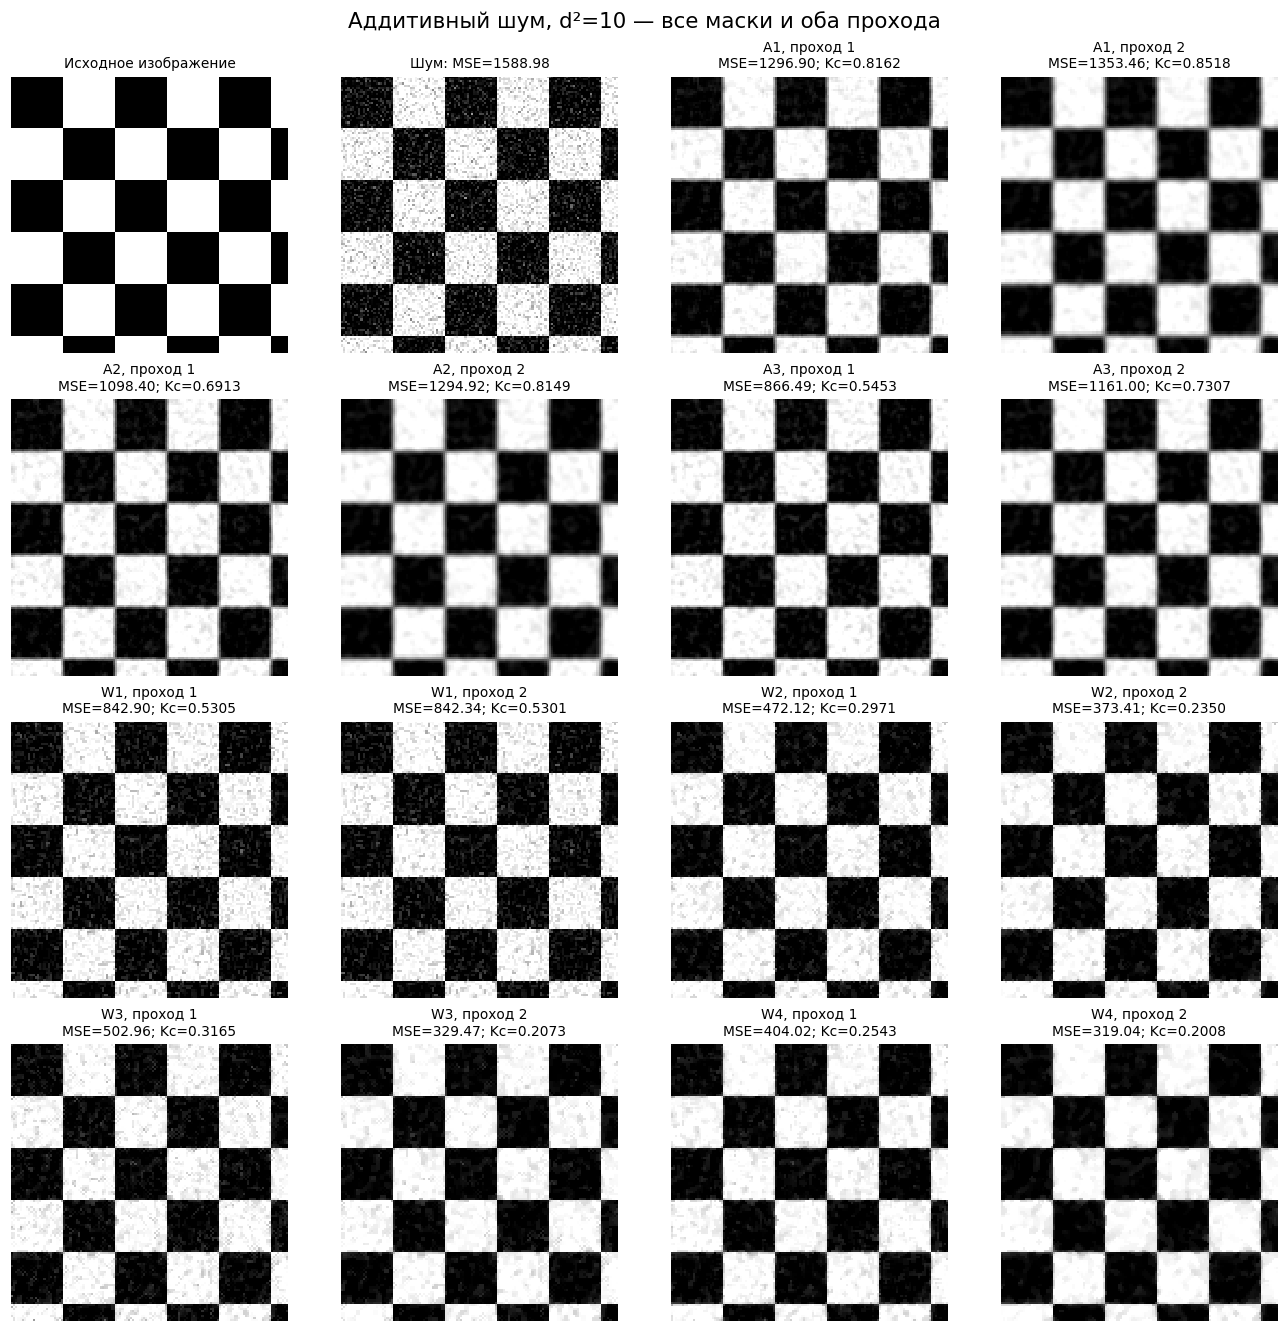

In [7]:
show_scenario(scenarios[0])

### 4.2. Аддитивный шум, d²=1

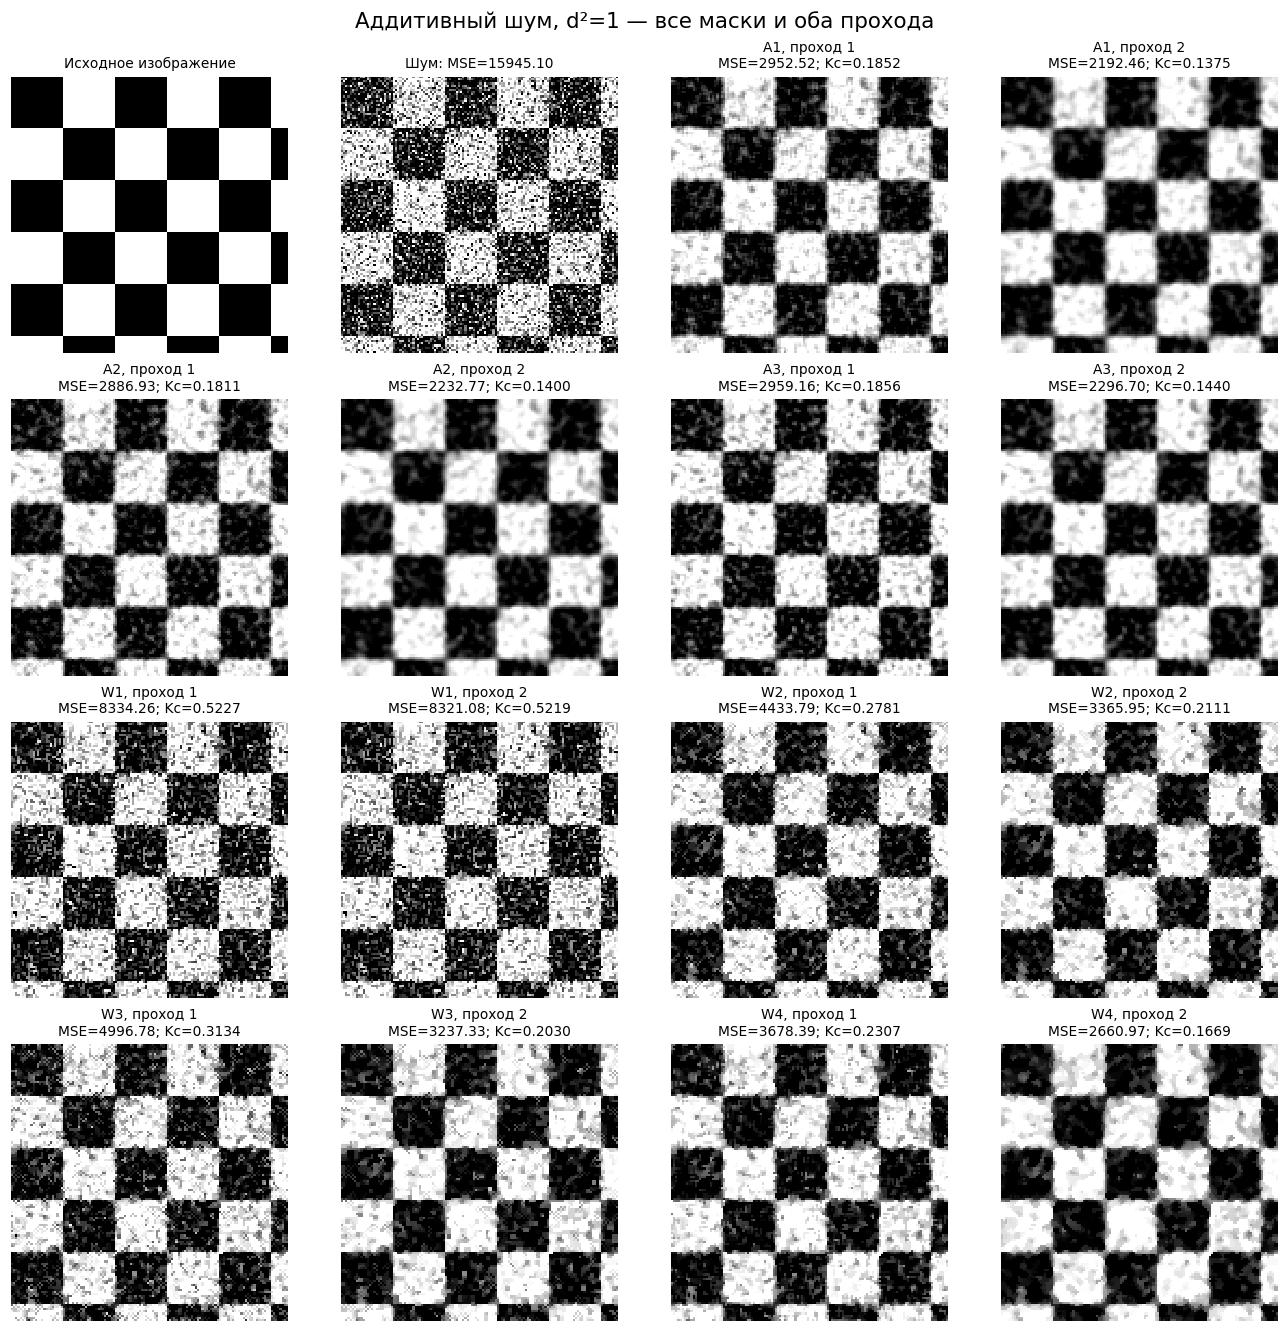

In [8]:
show_scenario(scenarios[1])

### 4.3. Импульсный шум, p=0.1

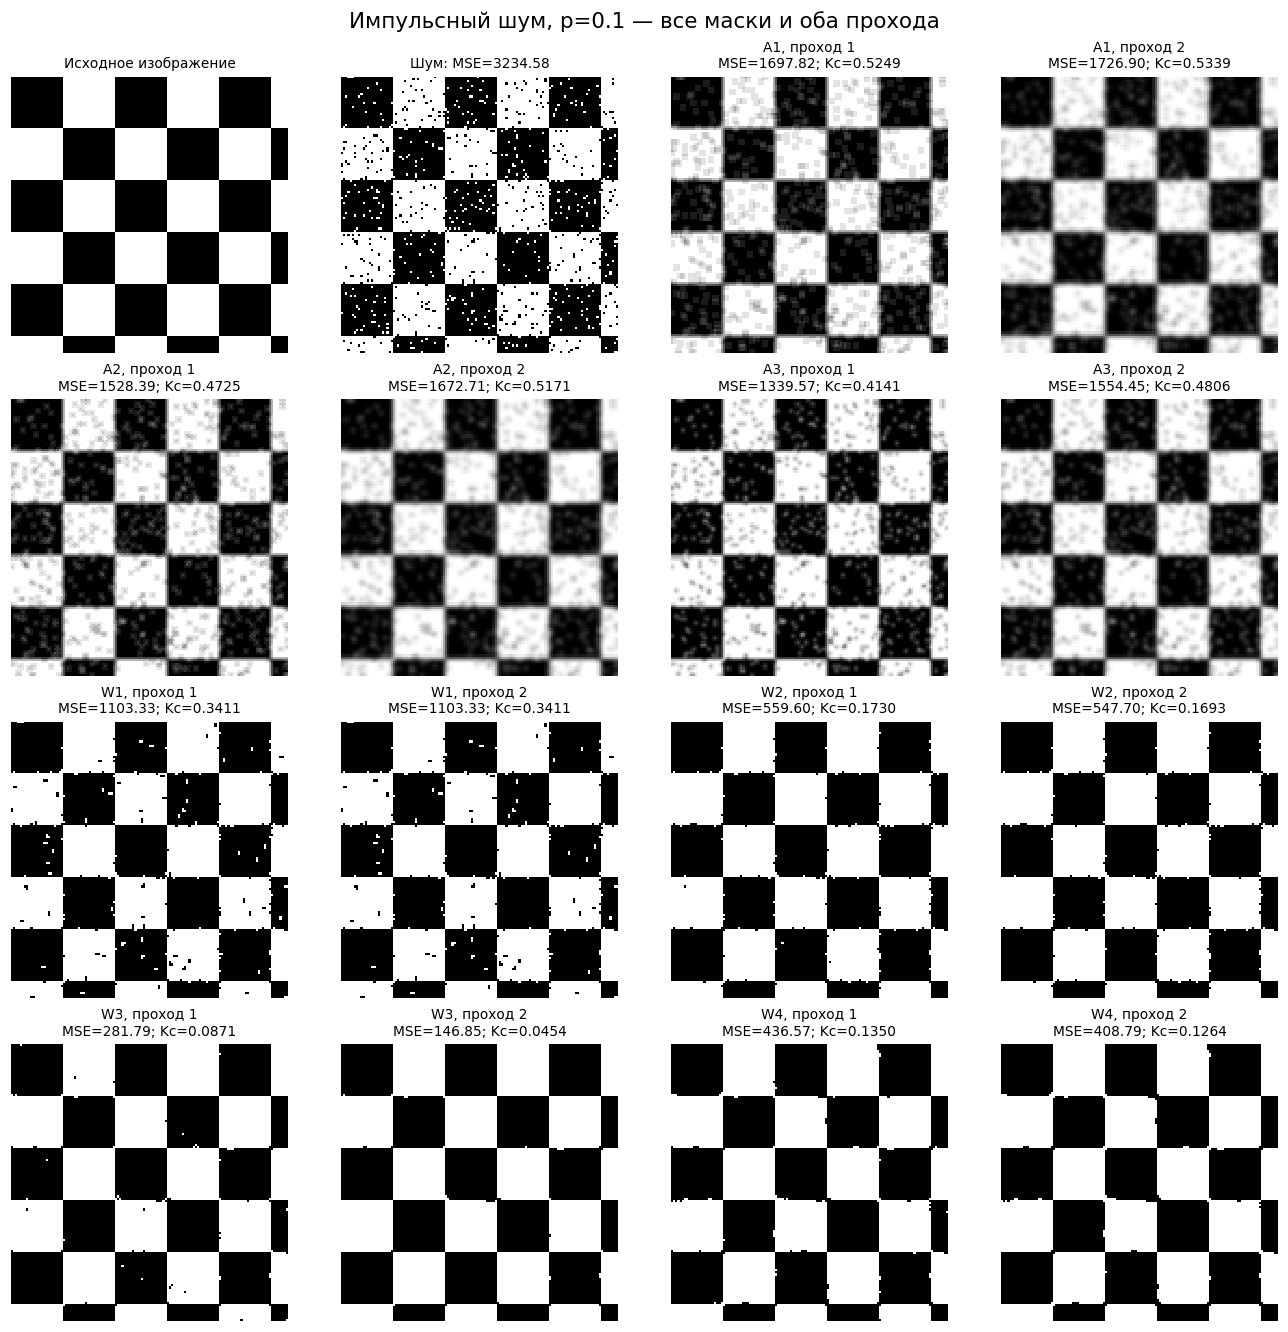

In [9]:
show_scenario(scenarios[2])

### 4.4. Импульсный шум, p=0.3

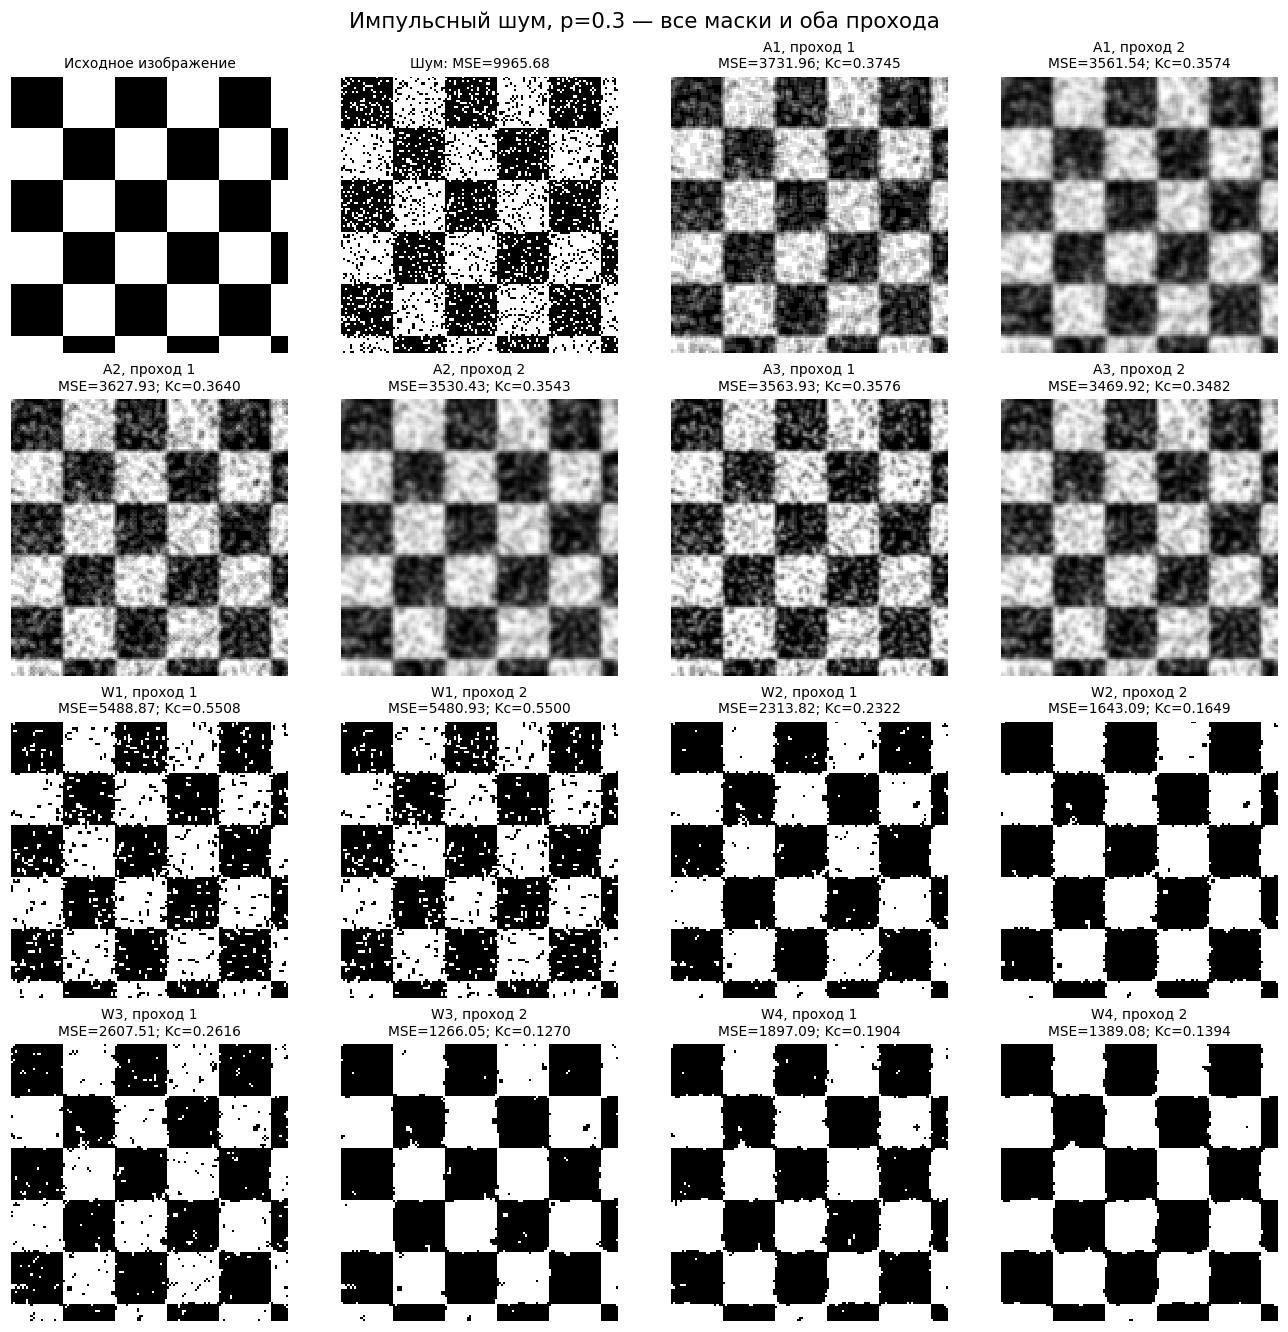

In [10]:
show_scenario(scenarios[3])

## 5. Гистограммы яркости и ошибок

Для каждого сценария ниже показаны исходное изображение, зашумлённое
и результаты обоих проходов маски с наименьшим Kc среди всех 14 комбинаций.
Гистограммы используют реальные значения, включая выход за диапазон 0–255.
Для исходного шума также показано распределение ошибки `y − x`.

Функция `scenario_records` выбирает из общей таблицы записи заданного сценария.
Из них по минимуму Kc определяется лучшая комбинация маски и прохода.
Для выбранной маски строятся гистограммы обоих проходов вместе с эталоном
и зашумлённым изображением. Для всех четырёх массивов внутри одного сценария
используются общие границы интервалов, рассчитанные по фактическому диапазону
яркостей. Вызов `linspace` задаёт 81 границу, то есть 80 интервалов.

Слева выводятся частоты яркостей, справа — гистограмма поэлементной ошибки
`noisy - x`. Гауссовский шум даёт распределение около нуля, а импульсный на
бинарном поле — значения −255, 0 и 255. Эти графики дополняют MSE:
они показывают форму распределения, которую одно число ошибки не описывает.

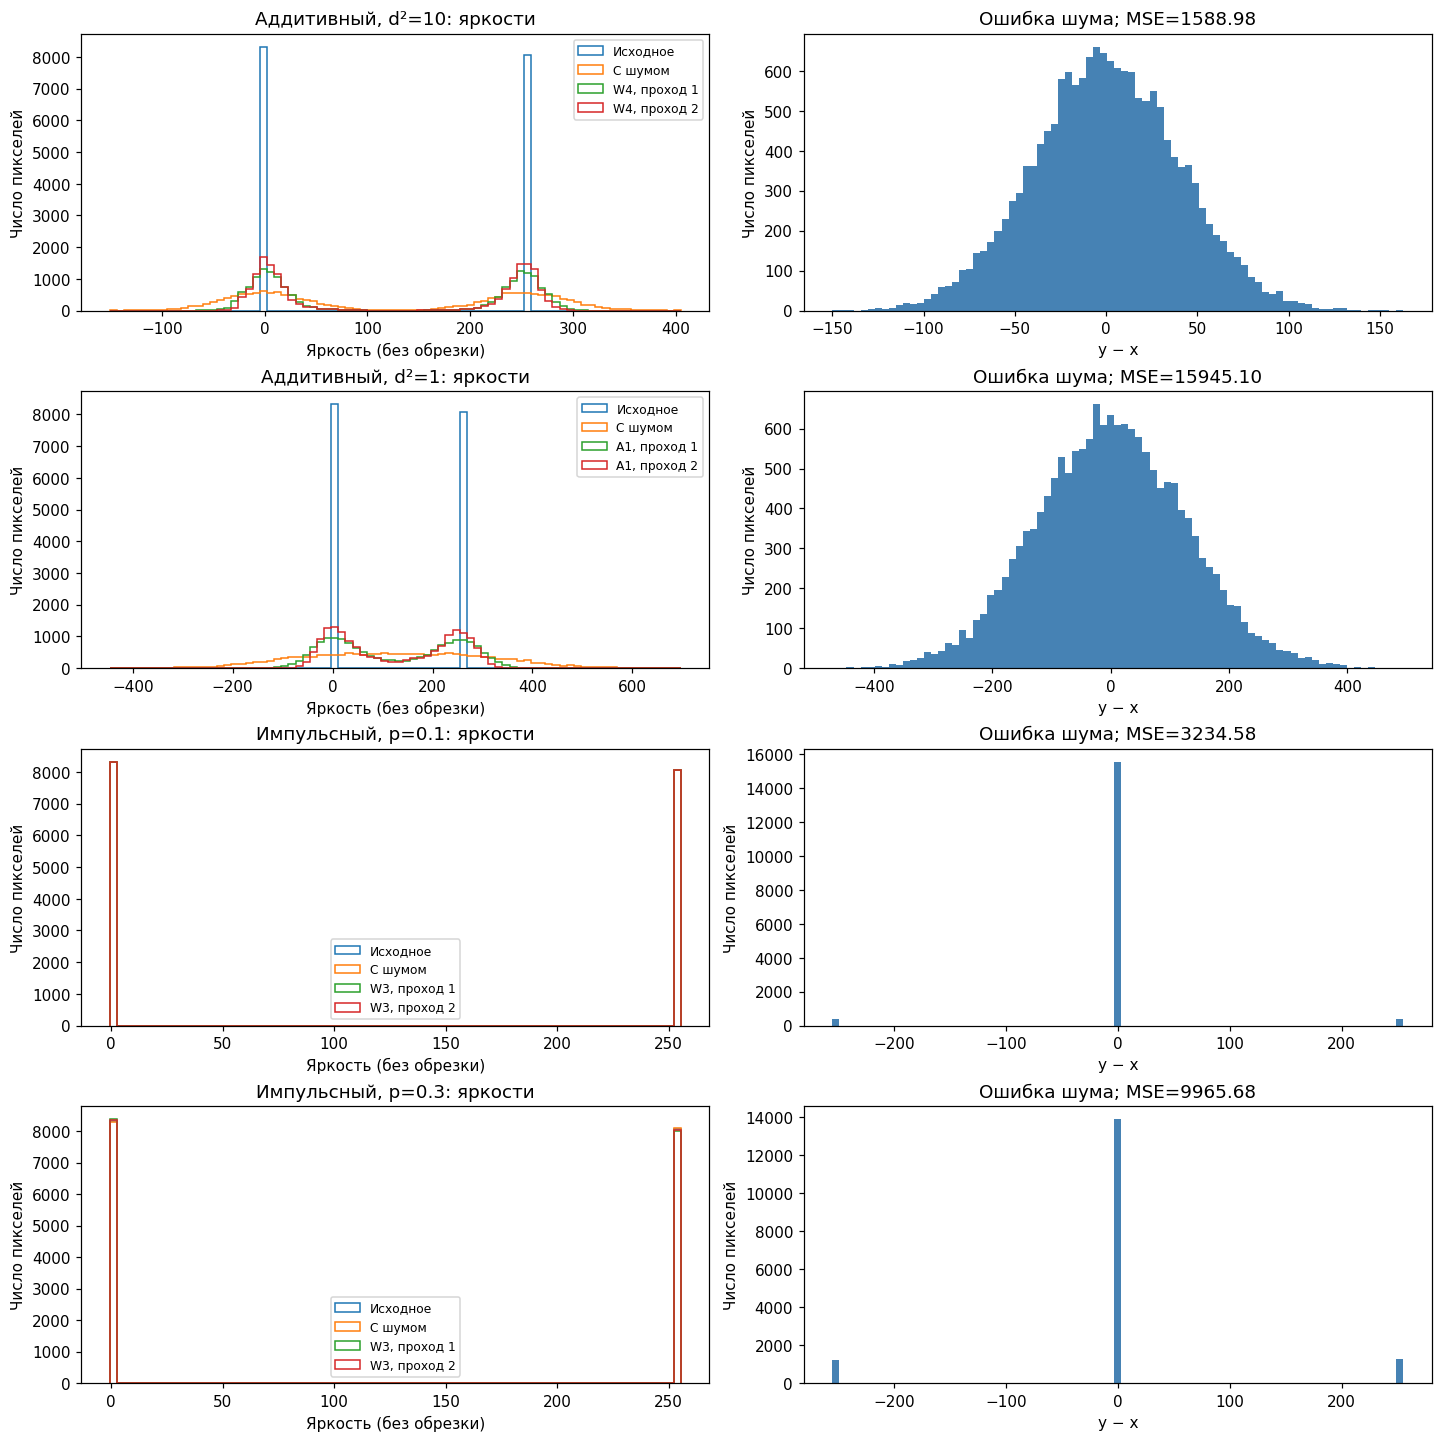

In [11]:
def scenario_records(s):
    return [r for r in records if r['kind'] == s['kind'] and r['parameter'] == s['parameter']]

fig, axes = plt.subplots(4, 2, figsize=(13, 13), layout='constrained')
for row, s in enumerate(scenarios):
    best = min(scenario_records(s), key=lambda r: r['kc'])
    arrays = [x, s['noisy'], s['results'][best['mask'], 1], s['results'][best['mask'], 2]]
    lo = min(float(a.min()) for a in arrays)
    hi = max(float(a.max()) for a in arrays)
    bins = np.linspace(lo - .5, hi + .5, 81)
    for a, label in zip(arrays, ('Исходное', 'С шумом', best['mask'] + ', проход 1', best['mask'] + ', проход 2')):
        axes[row, 0].hist(a.ravel(), bins=bins, histtype='step', label=label)
    axes[row, 0].set(title=f"{s['kind']}, {s['parameter']}: яркости",
                     xlabel='Яркость (без обрезки)', ylabel='Число пикселей')
    axes[row, 0].legend(fontsize=8)
    axes[row, 1].hist((s['noisy'] - x).ravel(), bins=81, color='steelblue')
    axes[row, 1].set(title=f"Ошибка шума; MSE={s['baseline']:.2f}",
                     xlabel='y − x', ylabel='Число пикселей')
plt.show()

## 6. Полная таблица результатов (56 строк)

| Тип шума | Параметр | Фильтр / маска | Проход | ε² (MSE) | Kc |
|---|---|---|---:|---:|---:|
| Аддитивный | d²=10 | Линейный A1 | 1 | 1296.902379 | 0.816186 |
| Аддитивный | d²=10 | Линейный A1 | 2 | 1353.462654 | 0.851781 |
| Аддитивный | d²=10 | Линейный A2 | 1 | 1098.399177 | 0.691261 |
| Аддитивный | d²=10 | Линейный A2 | 2 | 1294.915269 | 0.814935 |
| Аддитивный | d²=10 | Линейный A3 | 1 | 866.490521 | 0.545313 |
| Аддитивный | d²=10 | Линейный A3 | 2 | 1160.996219 | 0.730655 |
| Аддитивный | d²=10 | Медианный W1 | 1 | 842.898846 | 0.530466 |
| Аддитивный | d²=10 | Медианный W1 | 2 | 842.343134 | 0.530116 |
| Аддитивный | d²=10 | Медианный W2 | 1 | 472.120797 | 0.297122 |
| Аддитивный | d²=10 | Медианный W2 | 2 | 373.414173 | 0.235003 |
| Аддитивный | d²=10 | Медианный W3 | 1 | 502.958349 | 0.316529 |
| Аддитивный | d²=10 | Медианный W3 | 2 | 329.472350 | 0.207348 |
| Аддитивный | d²=10 | Медианный W4 | 1 | 404.016705 | 0.254262 |
| Аддитивный | d²=10 | Медианный W4 | 2 | 319.044226 | 0.200786 |
| Аддитивный | d²=1 | Линейный A1 | 1 | 2952.521411 | 0.185168 |
| Аддитивный | d²=1 | Линейный A1 | 2 | 2192.458788 | 0.137500 |
| Аддитивный | d²=1 | Линейный A2 | 1 | 2886.928798 | 0.181054 |
| Аддитивный | d²=1 | Линейный A2 | 2 | 2232.774929 | 0.140029 |
| Аддитивный | d²=1 | Линейный A3 | 1 | 2959.163150 | 0.185585 |
| Аддитивный | d²=1 | Линейный A3 | 2 | 2296.697332 | 0.144038 |
| Аддитивный | d²=1 | Медианный W1 | 1 | 8334.262737 | 0.522685 |
| Аддитивный | d²=1 | Медианный W1 | 2 | 8321.077910 | 0.521858 |
| Аддитивный | d²=1 | Медианный W2 | 1 | 4433.787045 | 0.278066 |
| Аддитивный | d²=1 | Медианный W2 | 2 | 3365.945680 | 0.211096 |
| Аддитивный | d²=1 | Медианный W3 | 1 | 4996.782271 | 0.313374 |
| Аддитивный | d²=1 | Медианный W3 | 2 | 3237.327425 | 0.203030 |
| Аддитивный | d²=1 | Медианный W4 | 1 | 3678.392699 | 0.230691 |
| Аддитивный | d²=1 | Медианный W4 | 2 | 2660.974662 | 0.166884 |
| Импульсный | p=0.1 | Линейный A1 | 1 | 1697.818163 | 0.524896 |
| Импульсный | p=0.1 | Линейный A1 | 2 | 1726.902210 | 0.533887 |
| Импульсный | p=0.1 | Линейный A2 | 1 | 1528.389130 | 0.472515 |
| Импульсный | p=0.1 | Линейный A2 | 2 | 1672.707799 | 0.517133 |
| Импульсный | p=0.1 | Линейный A3 | 1 | 1339.566743 | 0.414139 |
| Импульсный | p=0.1 | Линейный A3 | 2 | 1554.454279 | 0.480574 |
| Импульсный | p=0.1 | Медианный W1 | 1 | 1103.329468 | 0.341104 |
| Импульсный | p=0.1 | Медианный W1 | 2 | 1103.329468 | 0.341104 |
| Импульсный | p=0.1 | Медианный W2 | 1 | 559.602356 | 0.173006 |
| Импульсный | p=0.1 | Медианный W2 | 2 | 547.695923 | 0.169325 |
| Импульсный | p=0.1 | Медианный W3 | 1 | 281.785583 | 0.087117 |
| Импульсный | p=0.1 | Медианный W3 | 2 | 146.846008 | 0.045399 |
| Импульсный | p=0.1 | Медианный W4 | 1 | 436.569214 | 0.134969 |
| Импульсный | p=0.1 | Медианный W4 | 2 | 408.787537 | 0.126380 |
| Импульсный | p=0.3 | Линейный A1 | 1 | 3731.956312 | 0.374481 |
| Импульсный | p=0.3 | Линейный A1 | 2 | 3561.538192 | 0.357380 |
| Импульсный | p=0.3 | Линейный A2 | 1 | 3627.929855 | 0.364042 |
| Импульсный | p=0.3 | Линейный A2 | 2 | 3530.434425 | 0.354259 |
| Импульсный | p=0.3 | Линейный A3 | 1 | 3563.930297 | 0.357620 |
| Импульсный | p=0.3 | Линейный A3 | 2 | 3469.919086 | 0.348187 |
| Импульсный | p=0.3 | Медианный W1 | 1 | 5488.865662 | 0.550777 |
| Импульсный | p=0.3 | Медианный W1 | 2 | 5480.928040 | 0.549980 |
| Импульсный | p=0.3 | Медианный W2 | 1 | 2313.816833 | 0.232178 |
| Импульсный | p=0.3 | Медианный W2 | 2 | 1643.087769 | 0.164875 |
| Импульсный | p=0.3 | Медианный W3 | 1 | 2607.508850 | 0.261649 |
| Импульсный | p=0.3 | Медианный W3 | 2 | 1266.050720 | 0.127041 |
| Импульсный | p=0.3 | Медианный W4 | 1 | 1897.091675 | 0.190362 |
| Импульсный | p=0.3 | Медианный W4 | 2 | 1389.083862 | 0.139387 |

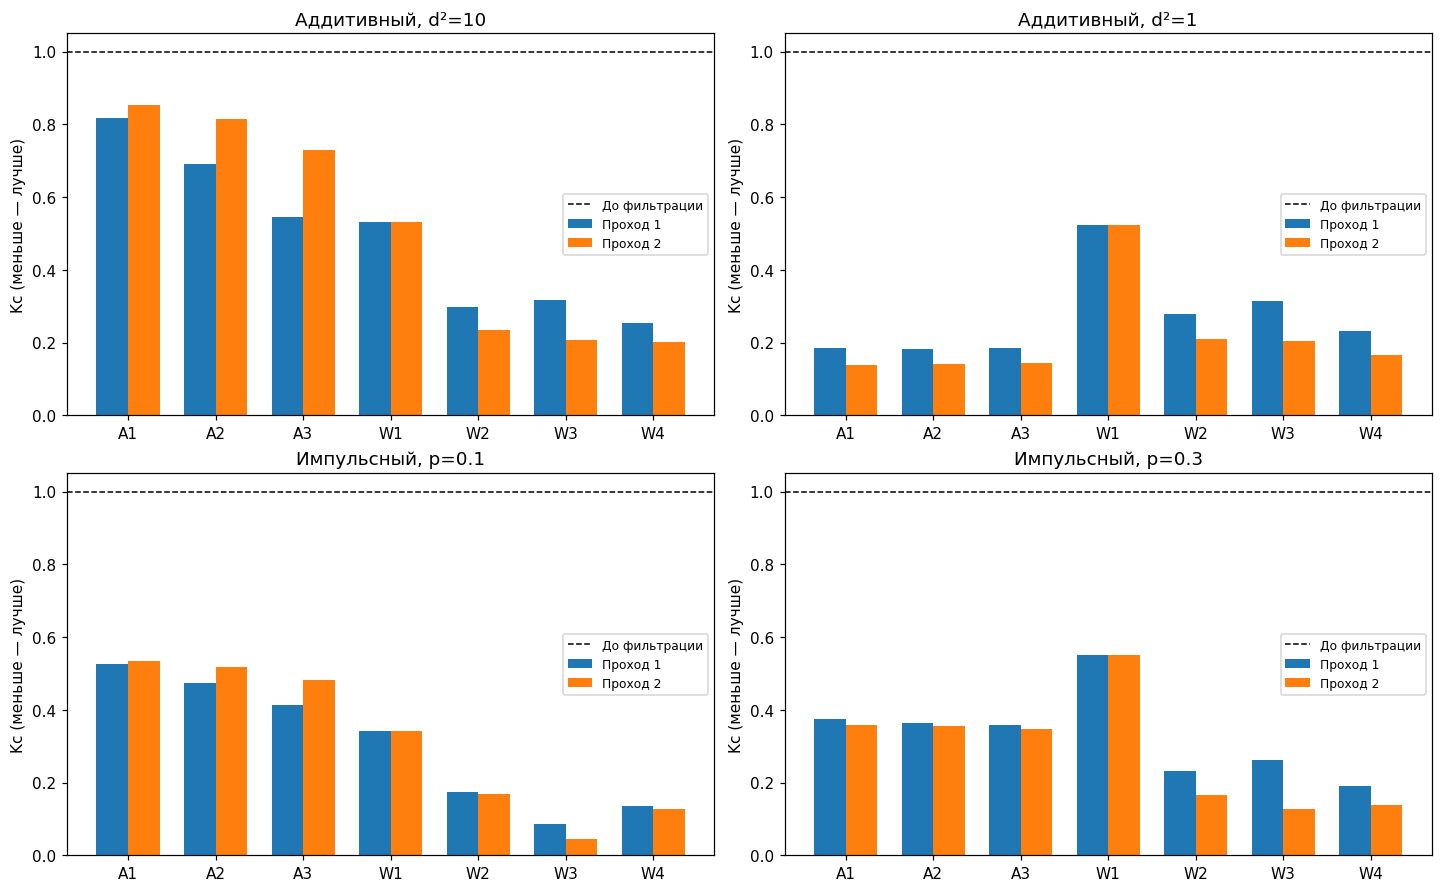

In [12]:
lines = ['| Тип шума | Параметр | Фильтр / маска | Проход | ε² (MSE) | Kc |',
         '|---|---|---|---:|---:|---:|']
for r in records:
    lines.append(f"| {r['kind']} | {r['parameter']} | {r['family']} {r['mask']} | "
                 f"{r['passage']} | {r['mse']:.6f} | {r['kc']:.6f} |")
display(Markdown('\n'.join(lines)))

fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
names = list(LINEAR_MASKS) + list(MEDIAN_MASKS)
positions = np.arange(len(names))
for ax, s in zip(axes.flat, scenarios):
    subset = scenario_records(s)
    for passage, offset in ((1, -.18), (2, .18)):
        values = [next(r['kc'] for r in subset if r['mask'] == name and r['passage'] == passage)
                  for name in names]
        ax.bar(positions + offset, values, width=.36, label=f'Проход {passage}')
    ax.axhline(1, color='black', linestyle='--', linewidth=1, label='До фильтрации')
    ax.set(xticks=positions, xticklabels=names, ylabel='Kc (меньше — лучше)',
           title=f"{s['kind']}, {s['parameter']}")
    ax.legend(fontsize=8)
plt.show()

## 7. Выводы по измеренным результатам

Численные выводы ниже автоматически рассчитываются из той же таблицы;
они сохраняют соответствие эксперименту при повторном запуске.

Для каждого сценария выбирается минимум Kc среди всех результатов,
а также отдельно среди линейных и медианных фильтров. Затем для каждой маски
сравниваются MSE двух проходов; в перечень улучшений попадают только маски
со строго меньшей ошибкой после второго прохода.

Последняя таблица сопоставляет MSE первого прохода одной и той же маски
при слабом и сильном шуме каждого типа. Все числа извлекаются из сохранённых
результатов эксперимента, поэтому текстовые численные выводы и таблица
формируются согласованно при последовательном запуске ячеек.

In [13]:
lines = []
for s in scenarios:
    subset = scenario_records(s)
    best = min(subset, key=lambda r: r['kc'])
    linear = min((r for r in subset if r['family'] == 'Линейный'), key=lambda r: r['kc'])
    median = min((r for r in subset if r['family'] == 'Медианный'), key=lambda r: r['kc'])
    improved = []
    for name in names:
        first, second = [next(r for r in subset if r['mask'] == name and r['passage'] == p) for p in (1, 2)]
        if second['mse'] < first['mse']:
            improved.append(name)
    lines.append(f"**{s['kind']} шум, {s['parameter']}.** Лучший результат: "
                 f"{best['mask']}, проход {best['passage']}, MSE={best['mse']:.4f}, "
                 f"Kc={best['kc']:.6f}. Лучший линейный: {linear['mask']} "
                 f"(проход {linear['passage']}, Kc={linear['kc']:.6f}); "
                 f"лучший медианный: {median['mask']} (проход {median['passage']}, "
                 f"Kc={median['kc']:.6f}). Второй проход уменьшил ошибку у "
                 f"{', '.join(improved) if improved else 'ни одной маски'}.")

display(Markdown('\n\n'.join(lines)))

lines = ['| Маска | MSE: d²=10 → d²=1 (проход 1) | MSE: p=0.1 → p=0.3 (проход 1) |',
         '|---|---:|---:|']
for name in names:
    errors = [mse(s['results'][name, 1], x) for s in scenarios]
    lines.append(f'| {name} | {errors[0]:.2f} → {errors[1]:.2f} | {errors[2]:.2f} → {errors[3]:.2f} |')
display(Markdown('\n'.join(lines)))

**Аддитивный шум, d²=10.** Лучший результат: W4, проход 2, MSE=319.0442, Kc=0.200786. Лучший линейный: A3 (проход 1, Kc=0.545313); лучший медианный: W4 (проход 2, Kc=0.200786). Второй проход уменьшил ошибку у W1, W2, W3, W4.

**Аддитивный шум, d²=1.** Лучший результат: A1, проход 2, MSE=2192.4588, Kc=0.137500. Лучший линейный: A1 (проход 2, Kc=0.137500); лучший медианный: W4 (проход 2, Kc=0.166884). Второй проход уменьшил ошибку у A1, A2, A3, W1, W2, W3, W4.

**Импульсный шум, p=0.1.** Лучший результат: W3, проход 2, MSE=146.8460, Kc=0.045399. Лучший линейный: A3 (проход 1, Kc=0.414139); лучший медианный: W3 (проход 2, Kc=0.045399). Второй проход уменьшил ошибку у W2, W3, W4.

**Импульсный шум, p=0.3.** Лучший результат: W3, проход 2, MSE=1266.0507, Kc=0.127041. Лучший линейный: A3 (проход 2, Kc=0.348187); лучший медианный: W3 (проход 2, Kc=0.127041). Второй проход уменьшил ошибку у A1, A2, A3, W1, W2, W3, W4.

| Маска | MSE: d²=10 → d²=1 (проход 1) | MSE: p=0.1 → p=0.3 (проход 1) |
|---|---:|---:|
| A1 | 1296.90 → 2952.52 | 1697.82 → 3731.96 |
| A2 | 1098.40 → 2886.93 | 1528.39 → 3627.93 |
| A3 | 866.49 → 2959.16 | 1339.57 → 3563.93 |
| W1 | 842.90 → 8334.26 | 1103.33 → 5488.87 |
| W2 | 472.12 → 4433.79 | 559.60 → 2313.82 |
| W3 | 502.96 → 4996.78 | 281.79 → 2607.51 |
| W4 | 404.02 → 3678.39 | 436.57 → 1897.09 |

### Объяснение различий

- При уменьшении $d^2$ с 10 до 1 заданная дисперсия гауссовского шума
  увеличивается в 10 раз. При росте $p$ с 0.1 до 0.3 возрастает доля импульсных
  замен. Абсолютную ошибку следует сравнивать по MSE; Kc нормирован на разную
  исходную ошибку, поэтому более низкий Kc при сильном шуме сам по себе
  не означает более точного восстановления.
- Линейные фильтры усредняют шум вместе с полезным сигналом. Для независимого
  шума на внутреннем участке постоянной яркости остаточная дисперсия после
  одного прохода равна $D_v\sum a_{ij}^2$: множители для A1, A2, A3 равны
  $1/9$, $0.12$, $0.140625$. A1 сильнее подавляет шум на плоском участке,
  а A3 сильнее сохраняет центральный пиксель. Вдоль границ клеток усреднение
  смешивает чёрный и белый и создаёт серые полосы; поэтому лучший результат
  на всём изображении не определяется только подавлением шума на фоне.
- Медиана подавляет одиночные импульсы без усреднения яркостей. W1 и W2
  с тройным центральным весом сильнее сохраняют локальную структуру, но чаще
  оставляют испорченный центральный пиксель. W3 использует крест, а W4 —
  девять элементов квадрата. Большее число соседей улучшает устойчивость
  к группам импульсов, но может скруглять углы и удалять малые детали.
  Сравнение всех четырёх масок видно в таблице и на изображениях.
- Второй проход дополнительно подавляет остаточные колебания и выбросы,
  но усиливает размытие у линейных фильтров и может менять углы у медианных.
  Его пользу оцениваем по фактическому снижению MSE для каждой маски,
  а не предполагаем заранее. Два прохода не доказывают достижения стабильной точки.
- Визуально следует отдельно оценивать чистоту внутренних областей и чёткость
  границ клеток. Минимум MSE учитывает оба эффекта сразу; он не гарантирует
  наилучшего субъективного качества. Численные победители приведены выше,
  а итоговое визуальное сопоставление выполнено ниже на увеличенных фрагментах.

Исследование относится к одной воспроизводимой реализации каждого шума и
шахматному полю с клеткой 24×24. Оно не устанавливает универсального победителя
для произвольных изображений. Мелких изолированных объектов в исходном поле нет,
поэтому их сохранение нельзя количественно оценить данным экспериментом.

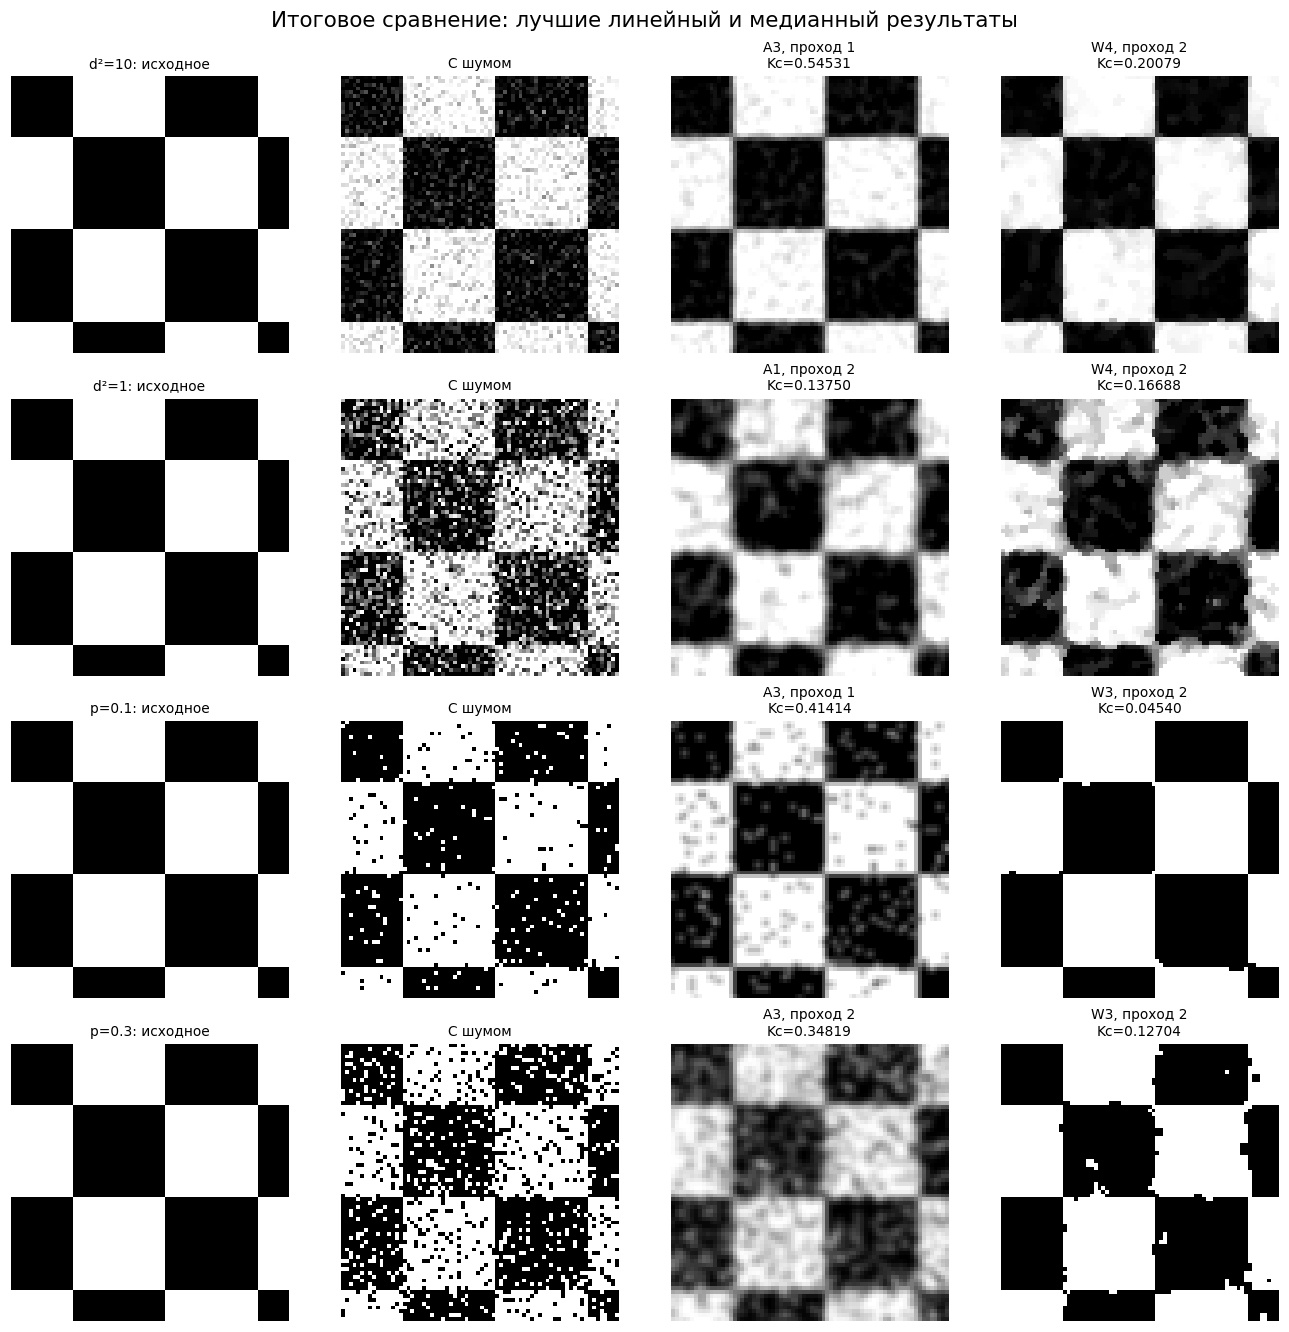

In [14]:
# Фрагмент включает внутренние области, прямые границы и углы клеток.
region = np.s_[8:80, 8:80]
fig, axes = plt.subplots(4, 4, figsize=(12, 12), layout='constrained')
for row, s in enumerate(scenarios):
    subset = scenario_records(s)
    best_linear = min((r for r in subset if r['family'] == 'Линейный'), key=lambda r: r['kc'])
    best_median = min((r for r in subset if r['family'] == 'Медианный'), key=lambda r: r['kc'])
    show_image(axes[row, 0], x[region], f"{s['parameter']}: исходное")
    show_image(axes[row, 1], s['noisy'][region], 'С шумом')
    for col, best in ((2, best_linear), (3, best_median)):
        show_image(axes[row, col], s['results'][best['mask'], best['passage']][region],
                   f"{best['mask']}, проход {best['passage']}\nKc={best['kc']:.5f}")
fig.suptitle('Итоговое сравнение: лучшие линейный и медианный результаты', fontsize=14)
plt.show()

### Визуальное сопоставление итогов для N = 27

При d²=10 результат W4 после двух проходов заметно чище внутри клеток,
чем A3 после одного; углы слегка скруглены. Минимум MSE у W4 согласуется
с общим визуальным впечатлением, хотя W3 после двух проходов очень близок
по качеству (Kc≈0.2073 против 0.2008).

При d²=1 A1 после двух проходов лучше подавляет зернистость внутри клеток,
чем лучший медианный W4. Это согласуется с меньшей MSE у A1, но цена —
более широкие размытые переходы: выбор только по чёткости границ мог бы отличаться.

Для обоих уровней импульсного шума W3 после двух проходов визуально существенно
лучше линейных фильтров: внутренние области практически очищены без серых полос.
При p=0.3 остаются отдельные дефекты и неровности границ, которых меньше
при p=0.1. W4 также хорошо очищает фон, но сильнее скругляет углы клеток.
Преимущество W3 по MSE в этих сценариях согласуется с сохранением формы поля.